# Ticket type and ticket number

Whether the ticket a passenger held says anything about their class, port of embarkation, cabin, fare and survival. Two parts of the ticket are looked at:

- **Ticket type**: the letters before the number (`PC`, `C.A.`, `A/5`, `SOTON/O.Q.`), or Number only. Spellings of the same prefix are merged, so `A/5` and `A./5.` are one type.
- **Ticket number windows**: ranges of the number itself. A **band** keeps the length of the number and its first digit (`3xxxxx` is any 6-digit number starting with 3). A **window** keeps more leading digits: the first 3 for numbers of 6 or more digits and for PC tickets, otherwise the first 2 (`347xxx`, `26xx`, `PC 175xx`).

**Data.** All 1,309 passengers in train and test are used for class, port, cabin and fare. Survival is only known for the 891 train passengers.

**Fare per person.** `Fare` is the price of the whole ticket, so it is divided by the number of passengers holding that ticket.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, BASE = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
CLASS_C = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
PORT_C = {"C": "#2a78d6", "Q": "#eb6834", "S": "#1baf7a"}
PORT_N = {"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"}
SEQ = LinearSegmentedColormap.from_list("seq", ["#f3f2ee", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
})

def find_data():
    from pathlib import Path
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "complete_data.csv").exists():
            return p / "data" / "complete_data.csv"
c = pd.read_csv(find_data())

c["TicketCount"] = c.groupby("Ticket")["PassengerId"].transform("size")
c["FarePP"] = c["Fare"] / c["TicketCount"]
c["Deck"] = c["Cabin"].str[0].replace({"T": "G"})
c["CabinKnown"] = c["Cabin"].notna()

def raw_prefix(t):
    parts = t.split(" ")
    if t.replace(" ", "").isdigit():
        return ""
    return " ".join(parts[:-1]) if parts[-1].isdigit() else t
c["TicketType"] = c["Ticket"].map(lambda t: "Number only" if raw_prefix(t) == "" else re.sub(r"[./ ]", "", raw_prefix(t)).upper())
TT_NAME = (c[c["TicketType"] != "Number only"].assign(P=c["Ticket"].map(raw_prefix))
           .groupby("TicketType")["P"].agg(lambda s: s.value_counts().index[0])).to_dict()
TT_NAME.update({"Number only": "Number only", "Other prefixes": "Other prefixes"})
c["TicketNum"] = pd.to_numeric(c["Ticket"].str.extract(r"(\d+)$")[0])

counts_t = c["TicketType"].value_counts()
KEEP = counts_t[counts_t >= 8].index
c["TypeGroup"] = np.where(c["TicketType"].isin(KEEP), c["TicketType"], "Other prefixes")
TYPE_ORDER = ["Number only"] + [k for k in counts_t.index if k in KEEP and k != "Number only"] + ["Other prefixes"]

def windows(row):
    t, n = row["TicketType"], row["TicketNum"]
    pre = "" if t == "Number only" else TT_NAME[t] + " "
    if pd.isna(n):
        return pd.Series([pre.strip(), pre.strip()])
    s = str(int(n)); d = len(s)
    k = min(d, 3 if (d >= 6 or t == "PC") else 2 if d >= 4 else 1)
    return pd.Series([pre + s[0] + "x" * (d - 1), pre + s[:k] + "x" * (d - k)])
c[["Band", "Window"]] = c.apply(windows, axis=1)
c["FareBand"] = pd.qcut(c["FarePP"], 5, labels=["lowest 20%", "20-40%", "40-60%", "60-80%", "top 20%"])
c["GroupSize"] = c["TicketCount"].clip(upper=5).map(lambda v: "5+" if v == 5 else str(v))
c["PclassName"] = c["Pclass"].map({1: "1st", 2: "2nd", 3: "3rd"})
tr = c[c["Survived"].notna()]
OVERALL = tr["Survived"].mean()
display(Markdown(
    f"{len(c):,} passengers on {c['Ticket'].nunique():,} distinct tickets. "
    f"{(c['TicketType'] == 'Number only').mean():.0%} hold a number-only ticket. "
    f"The survival rate for all train passengers is {OVERALL:.0%}."
))

1,309 passengers on 929 distinct tickets. 73% hold a number-only ticket. The survival rate for all train passengers is 38%.

## Findings

- **Ticket type mostly restates class and port.** PC tickets are all 1st class and 78% Cherbourg. A/5, A/4, SOTON/O.Q., STON/O 2. and C are all 3rd class and almost all Southampton. SC/PARIS is 2nd class Cherbourg. But 73% of passengers hold a number-only ticket, so type alone guesses class right for 65% of passengers, against 54% with no ticket information.
- **The ticket number says far more than the type.** For 6-digit number-only tickets the first digit is the class: every 1xxxxx is 1st class, every 2xxxxx 2nd, every 3xxxxx 3rd. Across all tickets, the number band guesses class right for 96% of passengers and the window for 98%.
- **Windows also pick out port.** All 90 passengers on 26xx tickets are 3rd class from Cherbourg. 330xxx, 367xxx, 368xxx and 382xxx are entirely Queenstown. Within PC, the Cherbourg share rises from 38% in PC 174xx to 96% in PC 177xx. Port is guessed right for 88% of passengers from the window, 75% from the type.
- **Fare follows the window.** The fare per person band (fifths) is guessed right for 74% of passengers from the window, 38% from the type, 21% with no ticket information.
- **Deck a little, sex not at all.** Some 1st class windows sit on one deck (19xxx: 94% deck C; PC 176xx: 88% deck B), lifting deck guesses from 32% to 48%. The ticket tells nothing about sex.
- **Survival beyond class and sex is weak.** The window guesses survival right for 68% of train passengers against 62% with no information, almost all of it through class. A handful of windows sit 20 points or more from what their class and sex predict, but each holds 8 to 18 train passengers.

## The ticket types

Types held by fewer than 8 passengers are folded into Other prefixes in the charts below. The number range is the lowest and highest ticket number of that type.

In [2]:
def rng(s):
    s = s.dropna()
    return "" if s.empty else f"{int(s.min()):,} to {int(s.max()):,}"
t = (c.groupby("TypeGroup")
     .agg(Passengers=("PassengerId", "size"), Tickets=("Ticket", "nunique"),
          Train=("Survived", "count"), Numbers=("TicketNum", rng))
     .reindex(TYPE_ORDER))
t.index = [TT_NAME[k] for k in t.index]
t.index.name = "Ticket type"
other = sorted(TT_NAME[k] for k in counts_t.index if k not in KEEP)
display(t.rename(columns={"Train": "In train", "Numbers": "Number range"}))
display(Markdown("Other prefixes: " + ", ".join(f"`{o}`" for o in other) + "."))

,Passengers,Tickets,In train,Number range
Ticket type,,,,
Number only,957,705,661,"680 to 3,101,298"
PC,92,48,60,"17,318 to 17,761"
C.A.,68,31,41,"2,144 to 49,867"
A/5,28,24,21,"851 to 21,175"
SOTON/O.Q.,24,22,15,"392,076 to 3,101,317"
STON/O 2.,21,20,18,"3,101,268 to 3,101,294"
SC/PARIS,19,13,11,"2,079 to 2,168"
W./C.,15,8,10,"6,607 to 14,266"
A/4,10,8,7,"20,589 to 54,510"


Other prefixes: `A. 2.`, `A/S`, `AQ/3.`, `AQ/4`, `C.A./SOTON`, `F.C.`, `Fa`, `LINE`, `LP`, `P/PP`, `PP`, `S.C./A.4.`, `S.O./P.P.`, `S.O.P.`, `S.P.`, `SC`, `SC/A.3`, `SC/AH`, `SC/AH Basle`, `SCO/W`, `SOTON/O2`, `STON/OQ.`, `SW/PP`, `W.E.P.`.

## How much each part of the ticket tells you

For each feature, the share of passengers whose value is guessed right by taking the most common value among **other** passengers in the same ticket type, band or window. The passenger's own value is left out, so a window holding one passenger cannot guess itself; where no one else shares the window, the guess falls back to the band, then the type. Grey is the guess with no ticket information: the most common value overall.

Deck is scored only for passengers with a cabin recorded, survival only for train passengers. Fare per person is split into five equal-sized bands, from the cheapest 20% to the most expensive 20%.

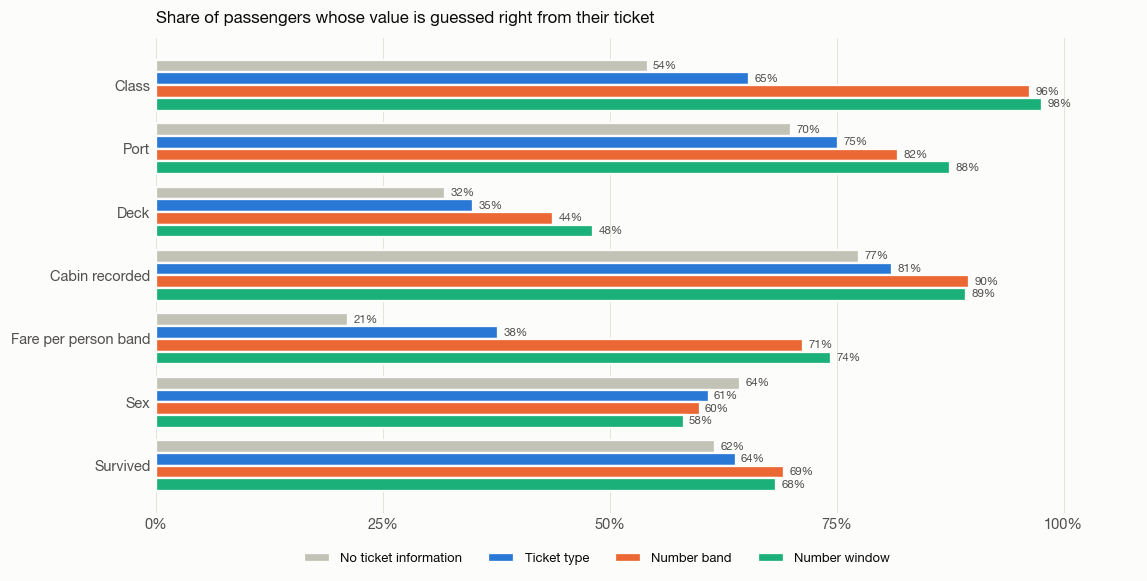

,No ticket information,Ticket type,Number band,Number window
Feature,,,,
Class,54.2%,65.3%,96.3%,97.6%
Port,69.9%,75.1%,81.8%,87.5%
Deck,31.9%,34.9%,43.7%,48.1%
Cabin recorded,77.5%,81.1%,89.6%,89.2%
Fare per person band,21.2%,37.7%,71.3%,74.4%
Sex,64.4%,60.9%,59.9%,58.1%
Survived,61.6%,63.9%,69.2%,68.4%


In [3]:
def loo_guess(df, target, levels):
    d = df[df[target].notna()].copy()
    d[target] = d[target].astype(str)
    guess = pd.Series(d[target].value_counts().index[0], index=d.index)
    hit = {"No ticket information": (guess == d[target]).mean()}
    fall = guess.copy()
    for name, col in levels:
        cnt = d.groupby([col, target]).size().rename("n").reset_index()
        g = np.full(len(d), None, dtype=object)
        lut = {k: v.set_index(target)["n"] for k, v in cnt.groupby(col)}
        for i, (key, own) in enumerate(zip(d[col], d[target])):
            s = lut[key].copy(); s[own] -= 1; s = s[s > 0]
            if len(s):
                g[i] = s.idxmax()
        g = pd.Series(g, index=d.index).fillna(fall)
        hit[name] = (g == d[target]).mean()
        fall = g
    return hit

LEVELS = [("Ticket type", "TicketType"), ("Number band", "Band"), ("Number window", "Window")]
FEATS = [("Class", "PclassName", c), ("Port", "Embarked", c), ("Deck", "Deck", c[c["CabinKnown"]]),
         ("Cabin recorded", "CabinKnown", c), ("Fare per person band", "FareBand", c),
         ("Sex", "Sex", c), ("Survived", "Survived", tr)]
res = pd.DataFrame({f: loo_guess(df, col, LEVELS) for f, col, df in FEATS}).T

fig, ax = plt.subplots(figsize=(11.5, 5.6))
series = [("No ticket information", BASE), ("Ticket type", BLUE), ("Number band", ORANGE), ("Number window", AQUA)]
h = 0.2
y = np.arange(len(res))
for k, (s, col) in enumerate(series):
    ax.barh(y + (k - 1.5) * h, res[s], height=h, color=col, edgecolor=SURFACE, linewidth=1.5, label=s, zorder=3)
    for i, v in enumerate(res[s]):
        ax.text(v + 0.006, i + (k - 1.5) * h, f"{v:.0%}", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(y, res.index); ax.invert_yaxis()
ax.set_xlim(0, 1.08); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.06), ncol=4, frameon=False, fontsize=8.5)
ax.set_title("Share of passengers whose value is guessed right from their ticket", loc="left", fontsize=11, pad=10)
plt.show()
tbl = (100 * res).round(1)
tbl.index.name = "Feature"
display(tbl.astype(str).add("%"))

Class, port and fare are where the ticket carries real information, and the number does most of the work. Cabin recorded and survival improve from type to band (81% to 90%, 64% to 69%) because both follow class; the window adds nothing further. Sex scores below the no-information guess at every level: the ticket carries nothing about it, and leaving out the passenger's own value costs a little in small groups.

In [4]:
COLS = [("Class", "Pclass", [1, 2, 3], ["1st", "2nd", "3rd"]),
        ("Port", "Embarked", ["C", "Q", "S"], ["Cherb.", "Queens.", "Southa."]),
        ("Deck, where recorded", "Deck", list("ABCDEFG"), ["A", "B", "C", "D", "E", "F", "G/T"])]

def profile(df, col, order, labels, title, ylabel, min_rows=None):
    """Row shares of class, port and deck per group, plus a text block of n, cabin recorded, fare and survival."""
    nrow = len(order)
    blocks = []
    for name, f, vals, vl in COLS:
        d = df[df[f].notna()]
        m = pd.crosstab(d[col], d[f], normalize="index").reindex(index=order, columns=vals).fillna(0)
        if f == "Deck":
            nn = d.groupby(col).size().reindex(order).fillna(0)
            m[nn == 0] = np.nan
        blocks.append((name, m, vl))
    g = df.groupby(col)
    stats = pd.DataFrame({
        "n": g.size(),
        "cabin": g["CabinKnown"].mean(),
        "fare": g["FarePP"].median(),
        "surv": g["Survived"].mean(),
        "ntr": g["Survived"].count(),
    }).reindex(order)
    H = 0.36 * nrow + 1.9
    fig, axes = plt.subplots(1, 4, figsize=(13.5, H),
                             gridspec_kw={"width_ratios": [3, 3, 7, 6.2], "wspace": 0.06})
    fig.subplots_adjust(top=1 - 1.0 / H, bottom=0.25 / H)
    for ax, (name, m, vl) in zip(axes, blocks):
        v = m.values.astype(float)
        ax.imshow(np.ma.masked_invalid(v), cmap=SEQ, vmin=0, vmax=1, aspect="auto", interpolation="nearest")
        ax.set_xlim(-0.5, v.shape[1] - 0.5)
        for i in range(nrow):
            for j in range(v.shape[1]):
                if np.isnan(v[i, j]) or v[i, j] < 0.005:
                    continue
                ax.text(j, i, f"{v[i, j]:.0%}", ha="center", va="center", fontsize=7.5,
                        color="white" if v[i, j] >= 0.55 else INK)
        ax.set_xticks(range(len(vl)), vl, fontsize=8)
        ax.xaxis.tick_top()
        ax.set_title(name, fontsize=9, color=INK2, pad=22)
        ax.set_yticks(range(nrow), labels if ax is axes[0] else [])
        for x in np.arange(-.5, len(vl)):
            ax.axvline(x, color=SURFACE, linewidth=2, clip_on=False)
        for yy in np.arange(-.5, nrow):
            ax.axhline(yy, color=SURFACE, linewidth=2, clip_on=False)
        ax.tick_params(which="both", length=0)
        ax.set_facecolor("#f6f6f4")
        for sp in ax.spines.values():
            sp.set_visible(False)
    axes[0].set_ylabel(ylabel)
    tx = axes[3]
    tx.set_xlim(0, 6.2); tx.set_ylim(nrow - 0.5, -0.5); tx.axis("off")
    heads = [(0.45, "Passengers"), (1.8, "Cabin\nrecorded"), (3.2, "Fare pp\nmedian"), (4.9, "Survived\n(train n)")]
    for x, hd in heads:
        tx.text(x, -0.9, hd, ha="center", va="bottom", fontsize=8, color=INK2)
    for i, r in enumerate(stats.itertuples()):
        tx.text(0.45, i, f"{int(r.n)}", ha="center", va="center", fontsize=8)
        tx.text(1.8, i, f"{r.cabin:.0%}", ha="center", va="center", fontsize=8)
        tx.text(3.2, i, "" if pd.isna(r.fare) else f"{r.fare:.2f}", ha="center", va="center", fontsize=8)
        if r.ntr:
            col = BLUE if r.surv > OVERALL + 0.1 else ORANGE if r.surv < OVERALL - 0.1 else INK
            tx.text(4.9, i, f"{r.surv:.0%} ({int(r.ntr)})", ha="center", va="center", fontsize=8, color=col)
        else:
            tx.text(4.9, i, "none in train", ha="center", va="center", fontsize=7.5, color=MUTED)
    fig.suptitle(title, x=0.125, ha="left", fontsize=11, y=1 - 0.1 / H)
    plt.show()
    return stats

display(Markdown(
    "**Reading the grids.** Each row is a group of passengers. The shaded cells are the share of the row in each class, "
    "port and deck, so each block of a row adds up to 100%. Deck is counted only over passengers with a cabin recorded; "
    "a row with no cabin recorded has an empty deck block. Survival is shown in blue when more than 10 points above the "
    f"{OVERALL:.0%} train average, orange when more than 10 points below. Rows with few train passengers should not be read as a rate."
))

**Reading the grids.** Each row is a group of passengers. The shaded cells are the share of the row in each class, port and deck, so each block of a row adds up to 100%. Deck is counted only over passengers with a cabin recorded; a row with no cabin recorded has an empty deck block. Survival is shown in blue when more than 10 points above the 38% train average, orange when more than 10 points below. Rows with few train passengers should not be read as a rate.

## Ticket type against class, port and cabin

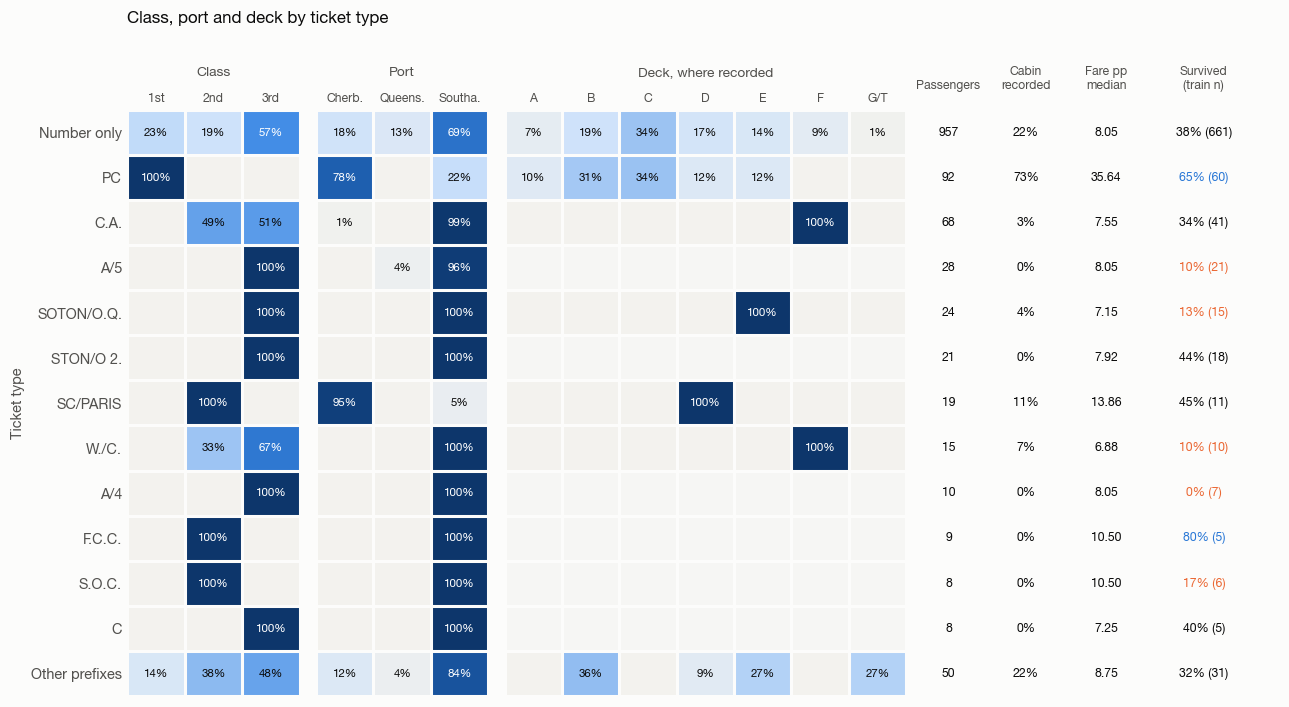

In [5]:
_ = profile(c, "TypeGroup", TYPE_ORDER, [TT_NAME[k] for k in TYPE_ORDER],
            "Class, port and deck by ticket type", "Ticket type")

Every prefixed type except C.A., W./C. and Other prefixes sits in a single class, and all but PC and SC/PARIS are almost entirely Southampton. Cabins are recorded mainly on PC tickets (73%) and on number-only tickets (22%, mostly 1st class). The survival differences between types are mostly class: PC (1st class) survived at 65%, A/5, A/4 and W./C. (3rd class) at 0 to 10%.

## Fare per person by ticket type

Each dot is one passenger, coloured by class. The black tick is the median for the type. The scale is logarithmic so that cheap fares are not squashed together. Passengers with a fare of 0 are left out.

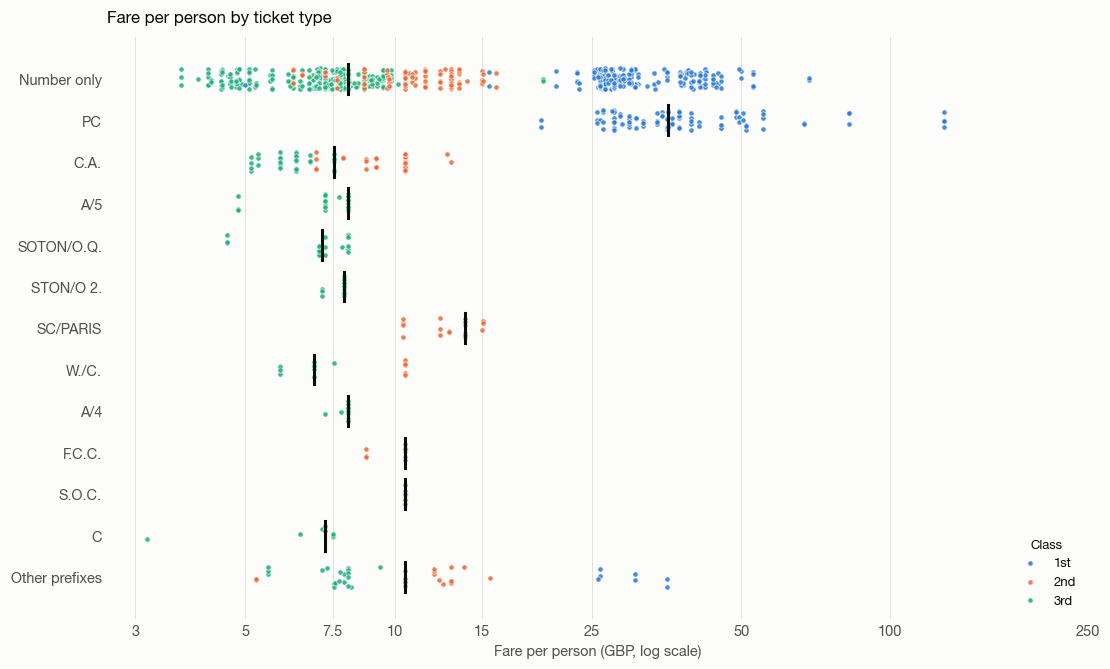

,1st,2nd,3rd
Median fare pp,,,
Number only,27.95,13.0,7.75
PC,35.64,,
C.A.,,10.5,6.32
A/5,,,8.05
SOTON/O.Q.,,,7.15
STON/O 2.,,,7.92
SC/PARIS,,13.86,
W./C.,,10.5,6.88
A/4,,,8.05


In [6]:
fig, ax = plt.subplots(figsize=(11.5, 0.42 * len(TYPE_ORDER) + 1.4))
rng_ = np.random.default_rng(0)
for i, k in enumerate(TYPE_ORDER):
    d = c[(c["TypeGroup"] == k) & (c["FarePP"] > 0)]
    for p in (3, 2, 1):
        dd = d[d["Pclass"] == p]
        ax.scatter(dd["FarePP"], i + rng_.uniform(-0.25, 0.25, len(dd)), s=12, color=CLASS_C[p],
                   edgecolor=SURFACE, linewidth=0.5, alpha=0.85, zorder=3,
                   label={1: "1st", 2: "2nd", 3: "3rd"}[p] if i == 0 else None)
    med = d["FarePP"].median()
    ax.plot([med, med], [i - 0.36, i + 0.36], color=INK, linewidth=2, zorder=4)
ax.set_xscale("log")
ticks = [3, 5, 7.5, 10, 15, 25, 50, 100, 250]
ax.set_xticks(ticks, [f"{v:g}" for v in ticks]); ax.minorticks_off()
ax.set_yticks(range(len(TYPE_ORDER)), [TT_NAME[k] for k in TYPE_ORDER]); ax.invert_yaxis()
ax.set_xlabel("Fare per person (GBP, log scale)")
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
h_, l_ = ax.get_legend_handles_labels()
order = [l_.index(x) for x in ["1st", "2nd", "3rd"]]
ax.legend([h_[o] for o in order], ["1st", "2nd", "3rd"], title="Class", loc="lower right", frameon=False, fontsize=8.5, title_fontsize=8.5)
ax.set_title("Fare per person by ticket type", loc="left", fontsize=11, pad=10)
plt.show()

w = (c[c["FarePP"] > 0].groupby(["TypeGroup", "PclassName"])["FarePP"].median().unstack().reindex(TYPE_ORDER).round(2))
w.index = [TT_NAME[k] for k in w.index]; w.index.name = "Median fare pp"; w.columns.name = None
display(w.fillna("").astype(str).replace("nan", ""))

Fare per person separates class cleanly within a type: 1st class above 20 GBP, 2nd class 10 to 15, 3rd class under 10. PC tickets cost more than number-only 1st class tickets (median 35.64 against 27.95 per person). Among 3rd class types, C.A. was cheapest (median 6.32) and SOTON/O.Q. 7.15, against 7.75 for number-only 3rd class. Fare adds little that class does not already say.

## Ticket number against fare, class and port

Number-only tickets, one dot per passenger, placed by ticket number (log scale) and fare per person. Left: coloured by class. Right: coloured by port of embarkation. The vertical lines mark where the number gains a digit.

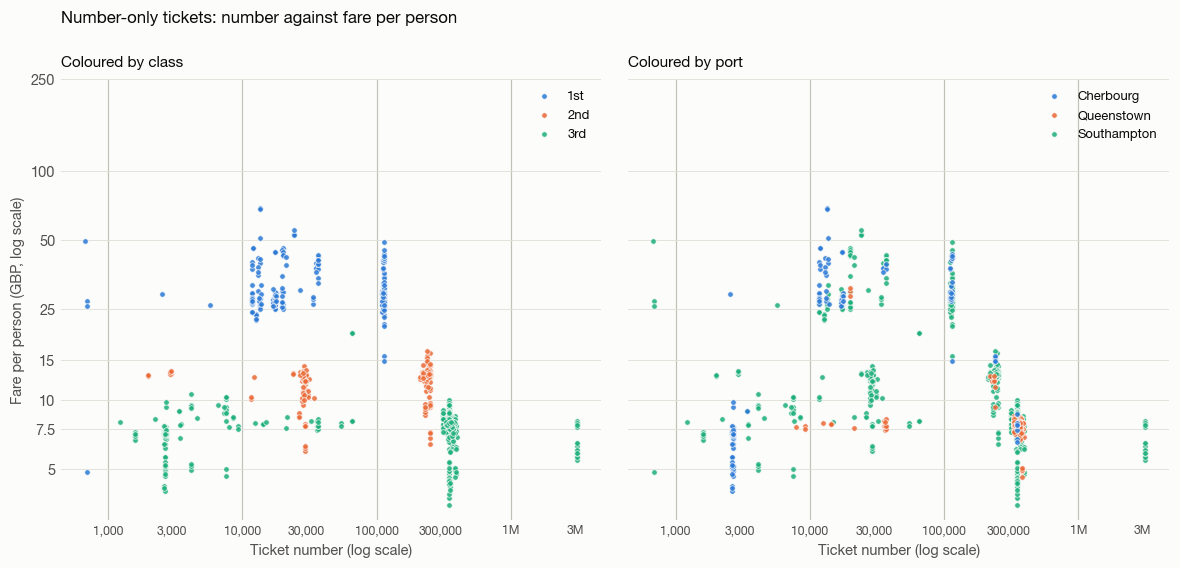

In [7]:
n = c[(c["TicketType"] == "Number only") & (c["FarePP"] > 0)].copy()
rng_ = np.random.default_rng(1)
n["y"] = n["FarePP"] * np.exp(rng_.normal(0, 0.03, len(n)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True, gridspec_kw={"wspace": 0.05})
for ax, (f, cols, names, ttl) in zip(axes, [
        ("Pclass", CLASS_C, {1: "1st", 2: "2nd", 3: "3rd"}, "Coloured by class"),
        ("Embarked", PORT_C, PORT_N, "Coloured by port")]):
    for k in list(cols)[::-1]:
        d = n[n[f] == k]
        ax.scatter(d["TicketNum"], d["y"], s=13, color=cols[k], edgecolor=SURFACE, linewidth=0.5, alpha=0.85, label=names[k], zorder=3)
    ax.set_xscale("log"); ax.set_yscale("log")
    for b in [1e3, 1e4, 1e5, 1e6]:
        ax.axvline(b, color=AXIS, linewidth=0.8, zorder=1)
    ax.set_xticks([1e3, 3e3, 1e4, 3e4, 1e5, 3e5, 1e6, 3e6], ["1,000", "3,000", "10,000", "30,000", "100,000", "300,000", "1M", "3M"], fontsize=8)
    ax.set_yticks([5, 7.5, 10, 15, 25, 50, 100, 250], ["5", "7.5", "10", "15", "25", "50", "100", "250"])
    ax.minorticks_off()
    ax.grid(axis="y", color=GRID, linewidth=0.6); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xlabel("Ticket number (log scale)")
    h_, l_ = ax.get_legend_handles_labels()
    ax.legend(h_[::-1], l_[::-1], loc="upper right", frameon=False, fontsize=8.5)
    ax.set_title(ttl, loc="left", fontsize=10, pad=8)
axes[0].set_ylabel("Fare per person (GBP, log scale)")
fig.suptitle("Number-only tickets: number against fare per person", x=0.125, ha="left", fontsize=11, y=1.0)
plt.show()

The number-only tickets fall into distinct blocks. 4-digit tickets are almost all 3rd class, and the 2,000 to 3,000 block is Cherbourg. 5-digit tickets from 11,000 to 20,000 are mostly 1st class, 28,000 to 30,000 2nd class. 6-digit tickets split exactly by first digit into 1st, 2nd and 3rd class, with the 3rd class block around 330,000 to 384,000 holding most Queenstown passengers. The 7-digit block at 3.1M is 3rd class Southampton, matching the STON/O 2. and SOTON/O.Q. tickets in the same range.

## Number-only tickets by band

The band is the length of the number and its first digit.

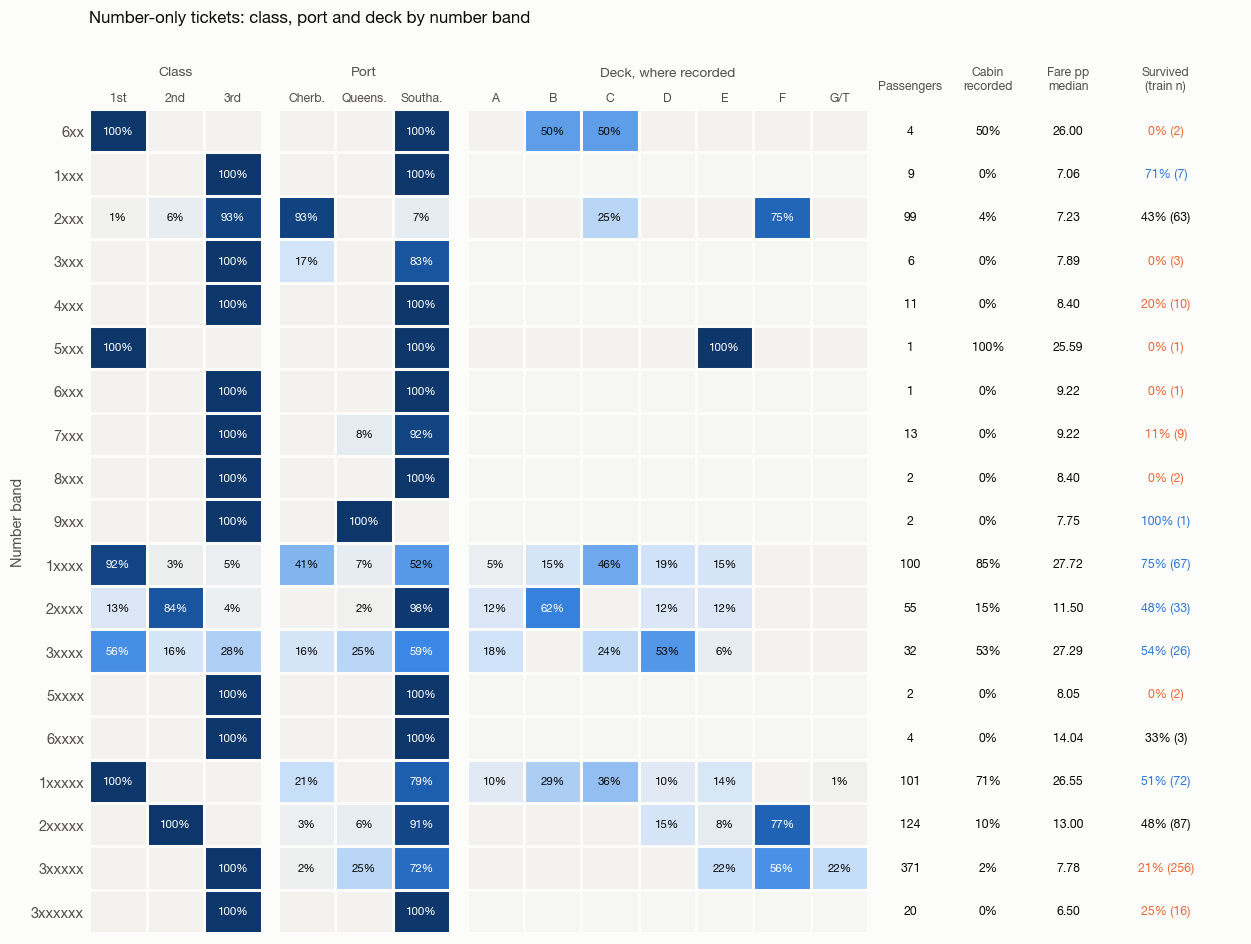

In [8]:
nb_ = c[c["TicketType"] == "Number only"].copy()
nb_["d"] = nb_["TicketNum"].astype(int).astype(str).str.len()
BAND_ORDER = (nb_.groupby("Band")["TicketNum"].min().sort_values().index.tolist())
_ = profile(nb_, "Band", BAND_ORDER, BAND_ORDER, "Number-only tickets: class, port and deck by number band", "Number band")

The band alone is enough for class on most tickets: 1xxxxx, 2xxxxx and 3xxxxx are each 100% one class, 1xxxx is 92% 1st class and 2xxxx 84% 2nd class. 2xxx is 93% 3rd class and 93% Cherbourg. The mixed bands are 3xxxx (56% 1st, 16% 2nd, 28% 3rd) and the small 3- and 5-digit bands. Port needs the finer window: 3xxxxx is 72% Southampton and 25% Queenstown overall.

## Number-only tickets by window

Windows with at least 5 passengers, in number order. Smaller windows are left out of this chart but kept in the scores at the top.

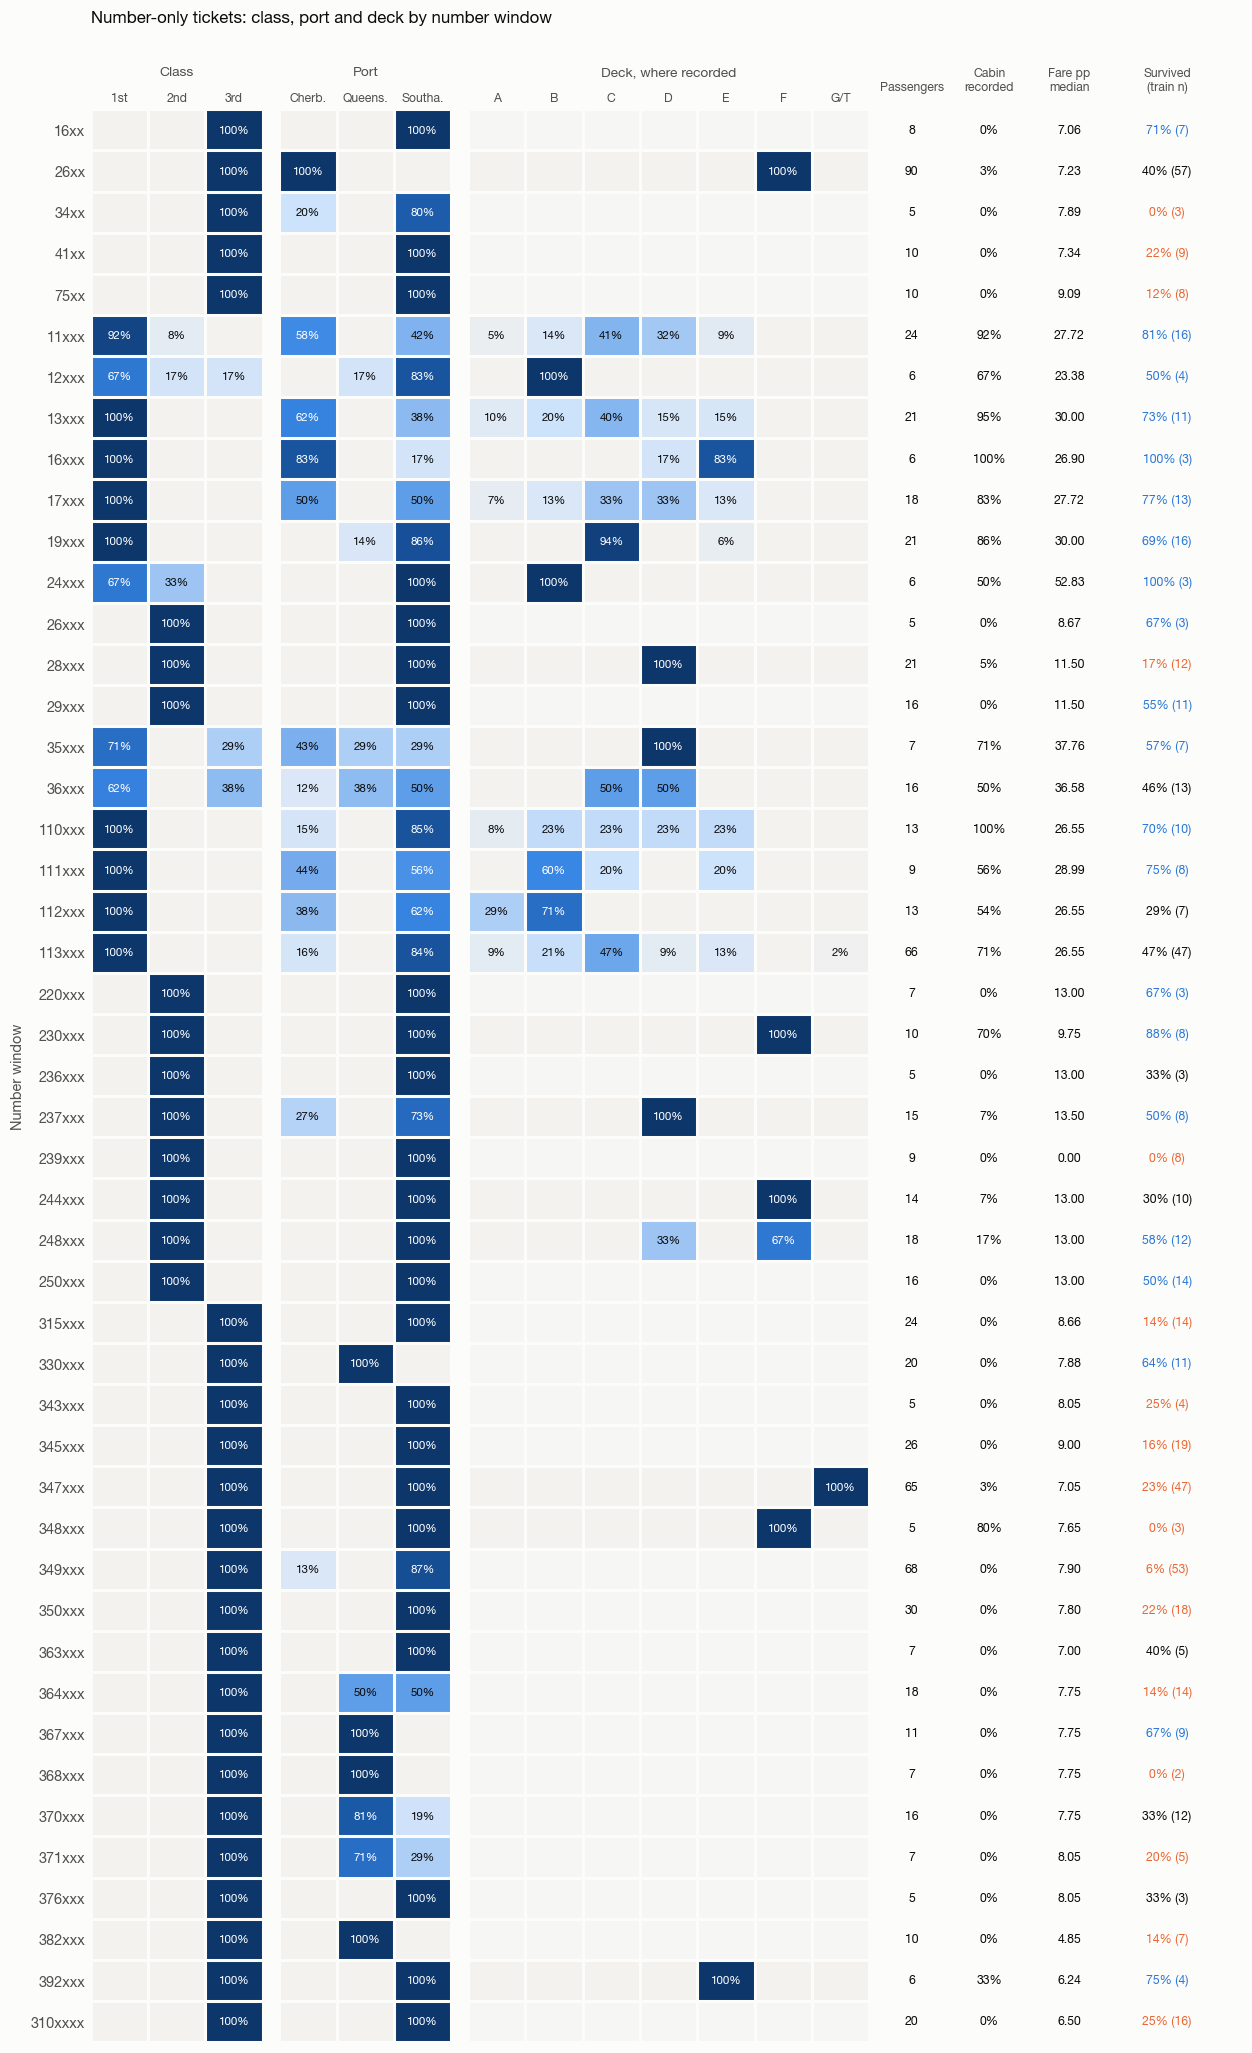

47 windows shown, holding 835 of the 957 number-only passengers.

In [9]:
wc = nb_["Window"].value_counts()
WIN_ORDER = [w for w in nb_.groupby("Window")["TicketNum"].min().sort_values().index if wc[w] >= 5]
_ = profile(nb_[nb_["Window"].isin(WIN_ORDER)], "Window", WIN_ORDER, WIN_ORDER,
            "Number-only tickets: class, port and deck by number window", "Number window")
display(Markdown(f"{len(WIN_ORDER)} windows shown, holding {int(wc[WIN_ORDER].sum())} of the {len(nb_)} number-only passengers."))

Inside each band, windows sort passengers further:

- **Port.** 26xx is 100% Cherbourg. 330xxx, 367xxx, 368xxx and 382xxx are 100% Queenstown, 370xxx 81% and 371xxx 71%. 345xxx, 347xxx, 349xxx and 350xxx, the largest 3rd class windows, are Southampton.
- **Deck.** Among 1st class windows, 19xxx is 94% deck C, 16xxx 83% deck E, 112xxx 71% deck B. 113xxx, the largest 1st class window (66 passengers), spreads over A to E.
- **Fare.** 239xxx is 9 2nd class passengers with a fare of 0; all 8 in train died, all male. 382xxx has the lowest median fare per person, 4.85.
- **Mixed windows.** 35xxx and 36xxx are the only windows mixing 1st and 3rd class, and they also mix all three ports.

## Prefixed tickets by window

The same view inside each ticket type with at least 15 passengers. Windows with fewer than 3 passengers are left out.

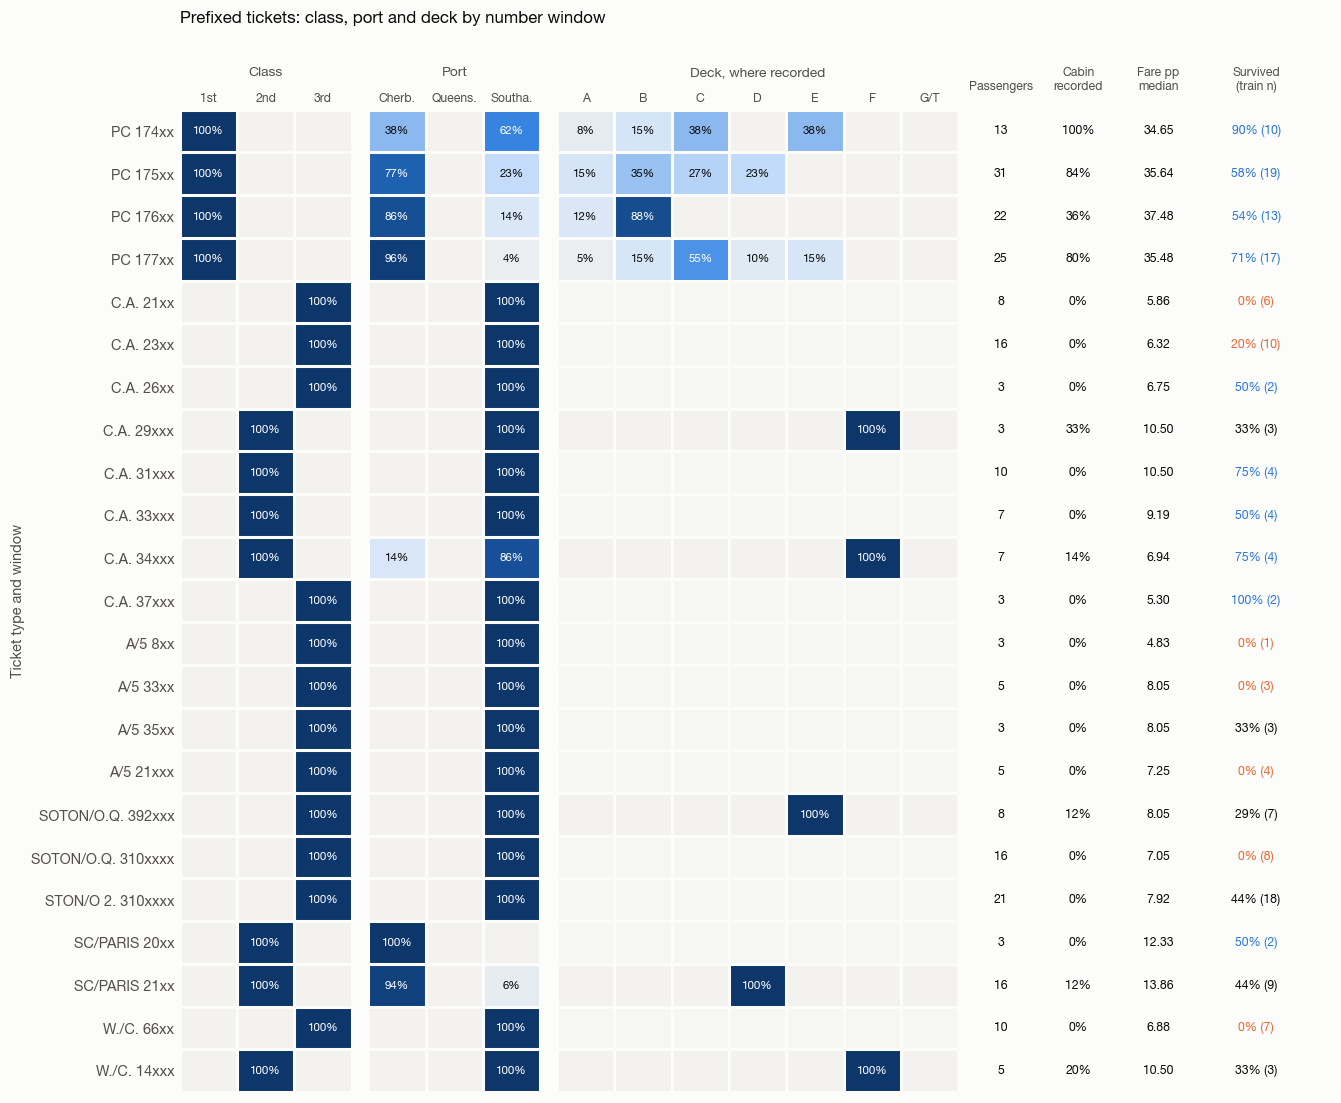

In [10]:
big = [k for k in TYPE_ORDER if k not in ("Number only", "Other prefixes") and counts_t[k] >= 15]
pp = c[c["TicketType"].isin(big)].copy()
pc = pp["Window"].value_counts()
pp = pp[pp["Window"].map(pc) >= 3]
PRE_ORDER = []
for k in big:
    PRE_ORDER += pp[pp["TicketType"] == k].groupby("Window")["TicketNum"].min().sort_values().index.tolist()
_ = profile(pp, "Window", PRE_ORDER, PRE_ORDER, "Prefixed tickets: class, port and deck by number window", "Ticket type and window")

The number resolves the class split inside C.A. and W./C.: C.A. 21xx, 23xx, 26xx and 37xxx are all 3rd class, C.A. 29xxx to 34xxx all 2nd class; W./C. 66xx is 3rd class, W./C. 14xxx 2nd. Within PC, the Cherbourg share rises with the number (38%, 77%, 86%, 96%), and PC 176xx is 88% deck B. SOTON/O.Q. 310xxxx and STON/O 2. 310xxxx share a number range and a class, yet none of the 8 SOTON/O.Q. passengers in train survived against 44% of the 18 STON/O 2. passengers.

## Survival by window, against class and sex

Class and sex drive most of survival, and the windows mostly follow class. To see whether a window says anything beyond them, each window's train survival rate is set against the rate expected from the class and sex of its passengers: the average, over its passengers, of the survival rate for their class and sex across all of train. Windows with at least 8 train passengers, number-only and prefixed together.

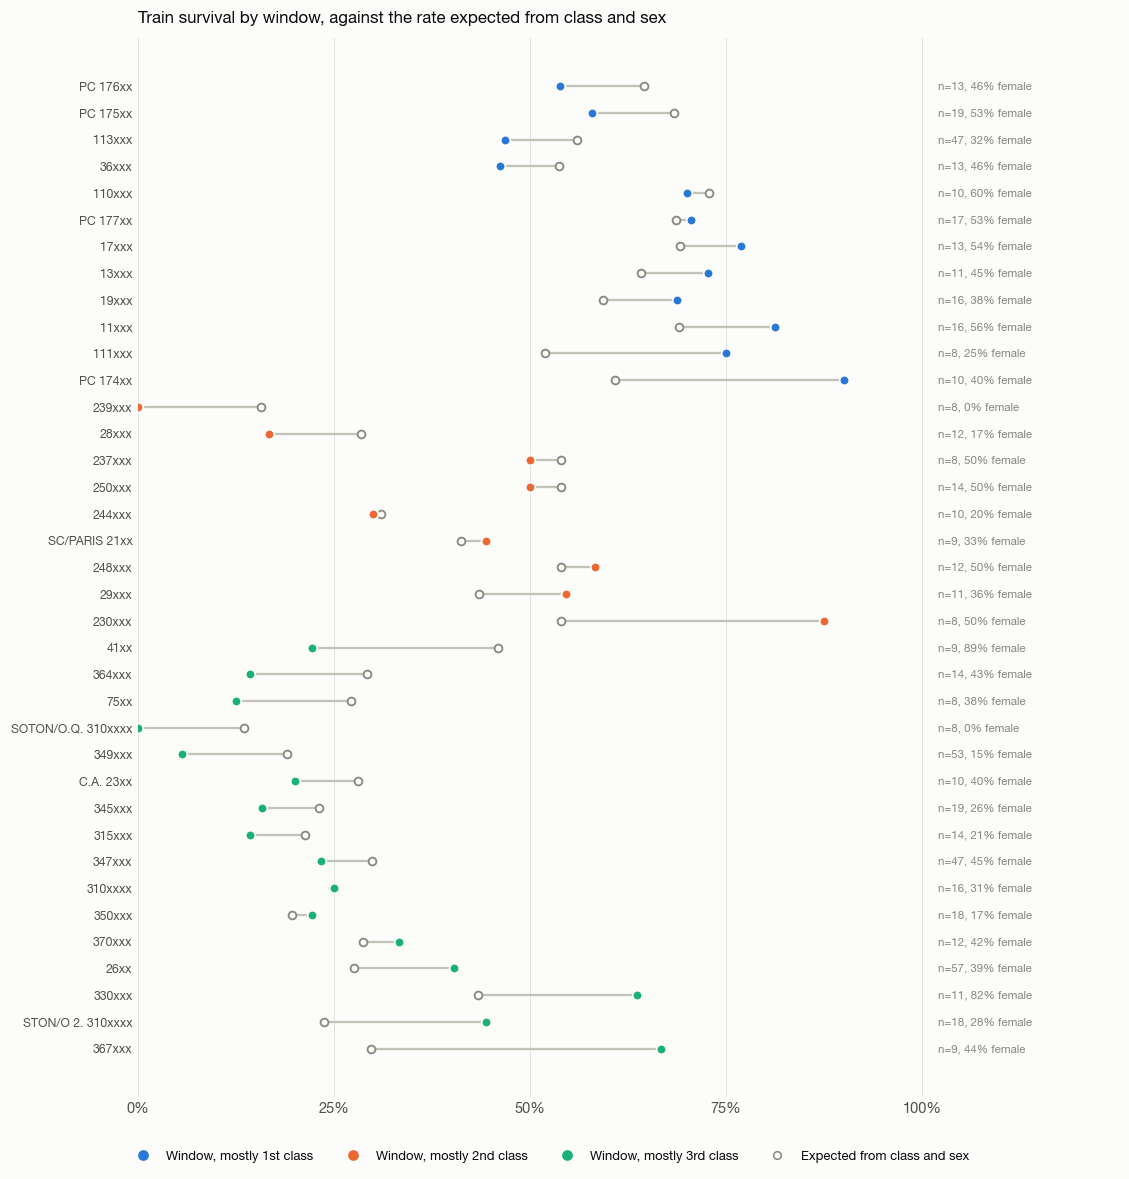

37 windows shown, holding 608 of the 891 train passengers. 7 sit 20 points or more from the expected rate. With 8 to 20 passengers in most windows, a gap of 20 points can arise by chance, so only the largest gaps are worth testing as a feature.

In [11]:
CS_RATE = tr.groupby(["Pclass", "Sex"])["Survived"].transform("mean")
t2 = tr.assign(Expected=CS_RATE)
g = t2.groupby("Window").agg(n=("Survived", "size"), surv=("Survived", "mean"), exp=("Expected", "mean"),
                             Pclass=("Pclass", lambda s: s.mode().iloc[0]),
                             female=("Sex", lambda s: (s == "female").mean()))
g = g[g["n"] >= 8].copy()
g["gap"] = g["surv"] - g["exp"]
g = g.sort_values(["Pclass", "gap"])
fig, ax = plt.subplots(figsize=(11.5, 0.3 * len(g) + 1.4))
y = np.arange(len(g))
for i, r in enumerate(g.itertuples()):
    ax.plot([r.exp, r.surv], [i, i], color=AXIS, linewidth=1.5, zorder=2)
    ax.scatter([r.exp], [i], s=26, color=SURFACE, edgecolor=MUTED, linewidth=1.2, zorder=3)
    ax.scatter([r.surv], [i], s=40, color=CLASS_C[r.Pclass], edgecolor=SURFACE, linewidth=1.2, zorder=4)
    ax.text(1.02, i, f"n={r.n}, {r.female:.0%} female", va="center", fontsize=7.5, color=MUTED)
ax.set_yticks(y, g.index, fontsize=8); ax.invert_yaxis()
ax.set_xlim(0, 1.25); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
from matplotlib.lines import Line2D
hd = [Line2D([], [], marker="o", ls="", color=CLASS_C[p], markersize=6, label=f"Window, mostly {l} class") for p, l in [(1, "1st"), (2, "2nd"), (3, "3rd")]]
hd.append(Line2D([], [], marker="o", ls="", markerfacecolor=SURFACE, markeredgecolor=MUTED, markersize=5, label="Expected from class and sex"))
ax.legend(handles=hd, loc="upper center", bbox_to_anchor=(0.42, -0.04), ncol=4, frameon=False, fontsize=8.5)
ax.set_title("Train survival by window, against the rate expected from class and sex", loc="left", fontsize=11, pad=10)
plt.show()
big_gap = g[g["gap"].abs() >= 0.2]
display(Markdown(
    f"{len(g)} windows shown, holding {int(g['n'].sum())} of the {len(tr)} train passengers. "
    f"{len(big_gap)} sit 20 points or more from the expected rate. With 8 to 20 passengers in most windows, "
    f"a gap of 20 points can arise by chance, so only the largest gaps are worth testing as a feature."
))

Most windows sit within 15 points of the rate their class and sex predict, so the ticket adds little to survival once class and sex are known. The largest gaps are above expected for 367xxx (67% against 30%, 9 passengers), 230xxx (88% against 54%, 8), PC 174xx (90% against 61%, 10) and STON/O 2. 310xxxx (44% against 24%, 18), and below for 41xx (22% against 46%, 9, 8 of them female). These windows are mostly a few families on consecutive tickets, so the gap is likely the family sharing one fate rather than the ticket range. The most solid gaps come from the large windows: 349xxx (53 in train) survived at 6% against 19% expected, 26xx (57) at 40% against 28%.